In [43]:
df_clean["Hour"] = (df_clean["Time"] / 3600) % 24

In [44]:
hour_analysis = df_clean.groupby("Hour")["Class"].agg(
    transactions="count",
    frauds="sum"
)

hour_analysis["fraud_rate"] = (
    hour_analysis["frauds"] /
    hour_analysis["transactions"]
) * 100

hour_analysis

,transactions,frauds,fraud_rate
Hour,,,
0.000000,3,0,0.0
0.000278,2,0,0.0
0.000278,4,0,0.0
0.000556,3,0,0.0
0.000556,2,0,0.0
...,...,...,...
23.997222,1,0,0.0
23.997778,3,0,0.0
23.998333,1,0,0.0


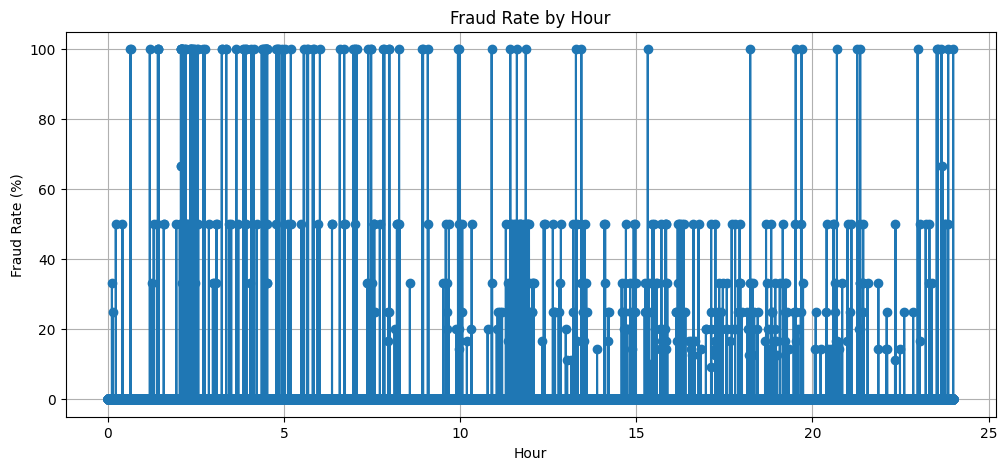

In [45]:
plt.figure(figsize=(12, 5))

plt.plot(
    hour_analysis.index,
    hour_analysis["fraud_rate"],
    marker="o"
)

plt.xlabel("Hour")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Hour")
plt.grid()

plt.show()

In [46]:
correlations = (
    df_clean
    .corr(numeric_only=True)["Class"]
    .sort_values(key=abs, ascending=False)
)

print(correlations.head(11))

Class    1.000000
V17     -0.313498
V14     -0.293375
V12     -0.250711
V10     -0.206971
V16     -0.187186
V3      -0.182322
V7      -0.172347
V11      0.149067
V4       0.129326
V18     -0.105340
Name: Class, dtype: float64


In [47]:
top_feature = correlations.index[1]

print("Strongest feature:", top_feature)
print("Correlation:", correlations[top_feature])

Strongest feature: V17
Correlation: -0.3134982729556793


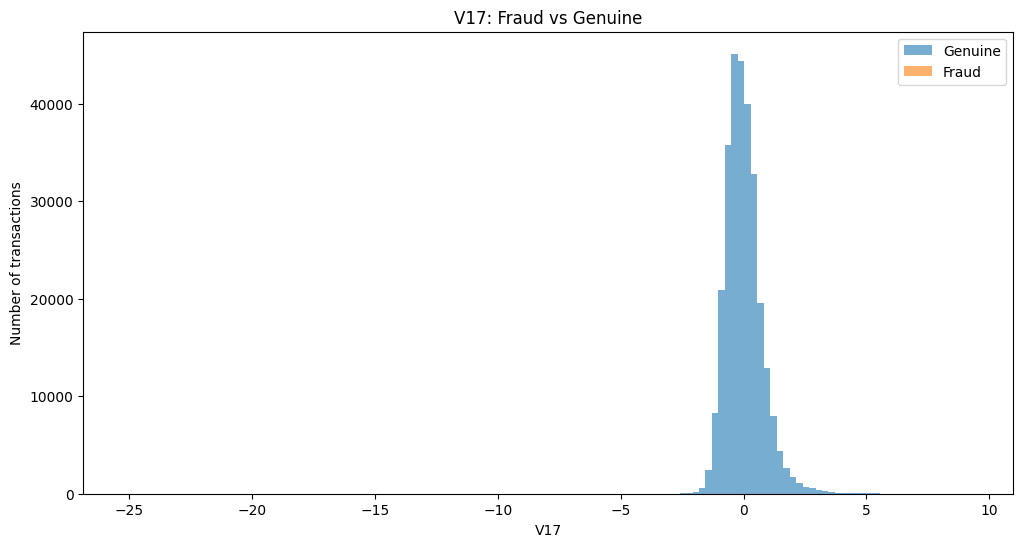

In [48]:
feature = top_feature

plt.figure(figsize=(12, 6))

plt.hist(
    df_clean.loc[df_clean["Class"] == 0, feature],
    bins=100,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    df_clean.loc[df_clean["Class"] == 1, feature],
    bins=100,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel(feature)
plt.ylabel("Number of transactions")
plt.title(f"{feature}: Fraud vs Genuine")
plt.legend()

plt.show()

In [49]:
v_features = [f"V{i}" for i in range(1, 29)]

comparison = pd.DataFrame({
    "genuine_mean": df_clean[df_clean["Class"] == 0][v_features].mean(),
    "fraud_mean": df_clean[df_clean["Class"] == 1][v_features].mean(),
})

comparison["difference"] = (
    comparison["fraud_mean"] -
    comparison["genuine_mean"]
)

comparison["abs_difference"] = comparison["difference"].abs()

comparison.sort_values(
    "abs_difference",
    ascending=False
)

,genuine_mean,fraud_mean,difference,abs_difference
V14,0.011668,-6.835946,-6.847614,6.847614
V3,0.012853,-6.729599,-6.742452,6.742452
V17,0.010963,-6.463285,-6.474249,6.474249
V12,0.009476,-6.103254,-6.112730,6.112730
V10,0.007663,-5.453274,-5.460937,5.460937
V7,0.010447,-5.175912,-5.186359,5.186359
V1,0.013439,-4.498280,-4.511719,4.511719
V4,-0.010440,4.472591,4.483031,4.483031
V16,0.007845,-4.000956,-4.008801,4.008801
V11,-0.006004,3.716347,3.722350,3.722350


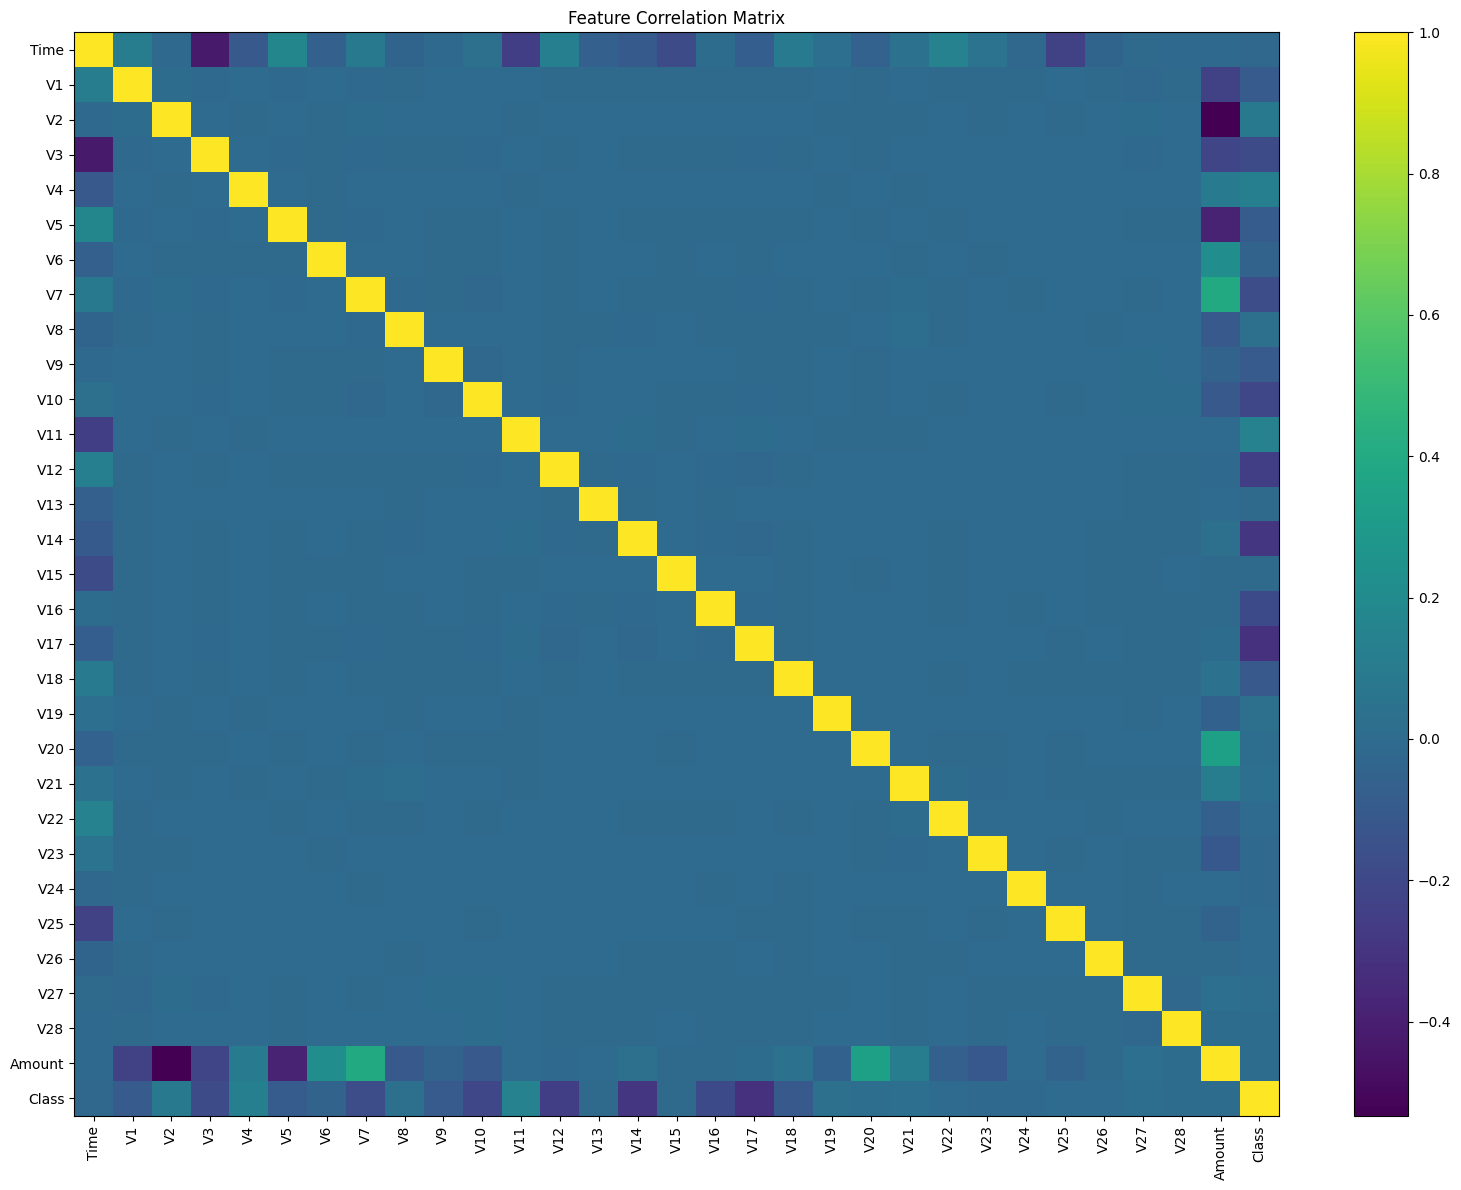

In [51]:
plt.figure(figsize=(16, 12))

corr_matrix = df_clean.drop(columns=["Hour"]).corr()

plt.imshow(corr_matrix, aspect="auto")

plt.colorbar()

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()

plt.show()

In [52]:
# Features and target
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFraud rate:")
print(y.mean() * 100)

X shape: (283726, 31)
y shape: (283726,)

Target distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Fraud rate:
0.1667101358352777


In [54]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

In [55]:
def dataset_summary(name, X_data, y_data):
    print(f"\n{name}")
    print("-" * 40)
    print("Samples:", len(X_data))
    print("Frauds:", y_data.sum())
    print("Genuine:", (y_data == 0).sum())
    print("Fraud rate:", f"{y_data.mean() * 100:.4f}%")

dataset_summary("TRAIN", X_train, y_train)
dataset_summary("VALIDATION", X_val, y_val)
dataset_summary("TEST", X_test, y_test)


TRAIN
----------------------------------------
Samples: 226980
Frauds: 378
Genuine: 226602
Fraud rate: 0.1665%

VALIDATION
----------------------------------------
Samples: 28373
Frauds: 48
Genuine: 28325
Fraud rate: 0.1692%

TEST
----------------------------------------
Samples: 28373
Frauds: 47
Genuine: 28326
Fraud rate: 0.1657%


In [56]:
train_idx = set(X_train.index)
val_idx = set(X_val.index)
test_idx = set(X_test.index)

print("Train ∩ Validation:", len(train_idx & val_idx))
print("Train ∩ Test:", len(train_idx & test_idx))
print("Validation ∩ Test:", len(val_idx & test_idx))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [58]:
scaler.fit_transform(X_train)

array([[ 1.04549909e+00,  1.14719836e+00, -1.04203246e+00, ...,
        -1.56192658e-01, -2.29433724e-01,  2.75087818e-01],
       [-2.98690019e-01, -6.77911305e-01,  9.91948465e-01, ...,
         1.53831425e-01, -3.31196981e-01,  1.34855957e+00],
       [ 6.78396673e-01,  9.77653618e-01,  1.62053993e-02, ...,
        -1.65819856e-01, -2.98808515e-01, -5.54168757e-01],
       ...,
       [ 1.19385202e+00, -4.52142124e-01,  7.06553792e-01, ...,
         2.88355918e-01, -2.09089210e-01,  6.10205845e-01],
       [-9.58244594e-01,  6.37814459e-01,  2.14682857e-01, ...,
         9.53313823e-02, -3.39294097e-01, -1.41324277e-01],
       [-8.96102723e-01,  5.23616867e-01, -1.32163174e-01, ...,
        -7.09689617e-03, -3.09550419e-01, -9.50494868e-04]])